# Heijunka (levelled) kit release with workcell setups and SPC

Copy of `phase2_assumptions_simulation.ipynb` that swaps the equal M860 → M970 → M1080 rotation for `release_mode="heijunka"` (README, Experiment 3). Everything else is unchanged: the station-group setup assumptions in [phase2_assumptions.md](phase2_assumptions.md), Year 3 resources, 75% setup reductions at every station (relative to the original project inputs; previously reduced stations are not reduced again), and SPC in both cells.

**Operational interpretation:**
- A workcell set means all parallel machines at one numbered station (for example, all six machines at 5-A), rather than all of Fabrication or Assembly.
- The complete station is set up once for **each product lot**, even when an earlier lot of that model was prepared. Setup happens when its first unit reaches the head of the station queue. Existing station work and maintenance finish first; all station machines are reserved during setup and while waiting for the setup team.
- Setup labor is `machine count × efficiency-adjusted setup time`. Elapsed setup is that labor divided by the assigned setup crew. Crew defaults to the station machine count; `SETUP_CREW` below overrides it. Operators come from the existing shared cell pools and are unavailable elsewhere while setting up. Crews are acquired atomically, in the pool's priority/FIFO order.
- A prepared lot remains ready at that station until it finishes. Its units can share machines with any other prepared product without further per-unit changeover setup. Zero setup inputs stay zero.
- **Arrivals (the change in this notebook):** one kit per recalculated arrival interval, with no station lot gates or WIP cap, in a **deterministic level sequence weighted by each model's planned kit volume**. Before each kit, the model furthest behind its kit share is released, so every model's kits, and its good output, arrive at an even rate matching its own demand. The cyclic rotation instead gives each model one third of the kits. The kit shares are printed below; they shift slightly with SPC because scrap allowances change.
- EOQ group identifiers retain the existing branch quantities, scrap planning, and component matching. They do not impose processing batches: matched assemblies leave immediately when their components are available.

These choices make the prose assumptions concrete. In particular, the station is unavailable during its group setup; prepared products may mix freely afterward. Part flow time starts at the oldest constituent kit's actual arrival; WIP counts component and assembly items.

**SPC in both cells:** Fabrication (1–8) and Assembly (9–12) use `scrap_scale=0.25`, a 75% reduction in every station/model scrap probability. Zero scrap stays zero. Scrap allowances, component requirements, and kit interarrival time are recalculated for the same planned finished output; therefore fewer input kits are required. The input table below reports the actual recalculated arrival interval.

## 1. Scenario inputs and setup crews

Change `YEAR` and `SETUP_CREW` here. This notebook uses the station-group setup policy throughout the detailed run. The tables show resources, product inputs, and elapsed setup times after efficiency and crew adjustment.

In [1]:
import os
import itertools
from dataclasses import replace
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from lcd_sim.params import get_scenario, MODELS, STATIONS, STATION_INFO
from lcd_sim.stats import run, run_replications
from lcd_sim import plots as P

YEAR = 3
N_REPS = 10
N_JOBS = max(1, min(8, (os.cpu_count() or 2) - 1))
SPC_SCRAP_SCALE = 0.25  # SPC in both Fab and Asm: 75% less scrap
SETUP_CREW = {}   # e.g. {"5-A": 3}; default is one operator per machine at each station
sc = get_scenario(YEAR, release_mode="heijunka", setup_scope="workcell", setup_crew=SETUP_CREW, scrap_scale=SPC_SCRAP_SCALE)
print(f"Year {YEAR}; {sc.warmup_weeks}-week warm-up; {sc.run_weeks}-week measurement")
kits = sc.annual_kits()
print(f"Arrivals: heijunka level sequence; {sc.kit_interarrival_min:.4f} productive min/kit")
print("Kit shares: " + ", ".join(f"{m} {kits[m] / sum(kits.values()):.1%}" for m in MODELS))
print("First 30 kits:", " ".join(m[1:] for m in itertools.islice(sc.heijunka_sequence(), 30)))
print(f"Operators per shift: {sc.operators}")
station_inputs, product_inputs = sc.describe()
display(product_inputs)
display(station_inputs)
setup_inputs = pd.DataFrame([
    {"Station": ws, "Machines": sc.machines[ws],
     "Setup crew": sc.setup_crew.get(ws, sc.machines[ws]),
     **{f"{model} elapsed setup (min)": sc.machines[ws] * sc.op_times(model, ws)["setup"] / sc.setup_crew.get(ws, sc.machines[ws])
        if station_inputs.loc[ws, f"Time/part {model}"] > 0 else None for model in MODELS}}
    for ws in STATIONS
]).set_index("Station")
display(setup_inputs)

pd.set_option("display.max_columns", 40, "display.width", 200, "display.float_format", "{:,.3f}".format)
print(f"SPC: Fab and Asm scrap probabilities multiplied by {sc.scrap_scale:.2f}")
scrap_inputs = pd.DataFrame({model: {ws: sc.scrap_rate(model, ws) for ws in STATIONS} for model in MODELS})
scrap_inputs.index.name = "Station"
display(scrap_inputs.rename(columns=lambda model: f"{model} scrap probability"))

Year 3; 2-week warm-up; 8-week measurement
Arrivals: heijunka level sequence; 1.1834 productive min/kit
Kit shares: M860 35.8%, M970 30.3%, M1080 33.9%
First 30 kits: 860 1080 970 860 1080 970 860 1080 970 860 1080 970 860 1080 970 860 1080 970 860 1080 860 970 1080 860 970 1080 860 970 1080 860
Operators per shift: {'Fab': 7, 'Asm': 13}


,Demand,EOQ,Lots_per_year,Planned_yield,Sent to KIT (1-M),Sent to KB (4-A),Sent to DISP (2-M),Sent to PWR (3-A/5-A),Sent to BL (6-A),Sent to ASM (7-M/8-A/9-M/10-M/11-A/12-M),Kits_per_year,Sent to ASM (8-A/9-M/10-M/11-A/12-M)
Model,,,,,,,,,,,,
M860,63877,754,85,0.9415,801,791,801,799,787,785.0,68085,NaN
M970,55296,596,93,0.9614,620,614,620,620,613,NaN,57660,611.0
M1080,61516,655,94,0.9565,685,676,685,684,674,NaN,64390,672.0


,Description,Type,Cell,Machines,Efficiency,Time/part M860,Time/part M970,Time/part M1080,Setup M860,Setup M970,...,Qty/lot M970,Qty/lot M1080,Scrap factor M860,Scrap factor M970,Scrap factor M1080,PM_every_units,PM_min,MTBF_hr,Repair_min,Units_between_failures
Station,,,,,,,,,,,,,,,,,,,,,
1-M,Unpack and label components,M,Fab,2,0.90,1.742,1.851,2.287,4.17,0.00,...,620.0,685.0,1.0621,1.0402,1.0455,NaN,NaN,NaN,NaN,NaN
2-M,Sanitize LC displays and PCBs,M,Fab,2,0.95,1.135,1.548,1.651,5.26,0.00,...,620.0,685.0,1.0621,1.0402,1.0455,NaN,NaN,100.0,10.0,4182.0
3-A,Connect display to power strip,A,Fab,2,1.05,0.564,1.404,1.686,1.19,2.38,...,620.0,684.0,1.0595,1.0389,1.0441,12000.0,10.0,50.0,30.0,2502.0
4-A,Tack keyboard inputs to display,A,Fab,1,1.02,0.969,0.484,0.678,1.96,2.45,...,614.0,676.0,1.0489,1.0298,1.0308,12000.0,20.0,75.0,60.0,6221.0
5-A,Bond power strip to PCB and LCD,A,Fab,6,0.99,2.697,6.459,7.251,3.79,15.15,...,620.0,684.0,1.0542,1.0350,1.0408,12000.0,20.0,250.0,120.0,2787.0
6-A,Insert backlights and sensors,A,Fab,3,0.95,1.242,1.964,3.308,2.63,0.00,...,613.0,674.0,1.0436,1.0272,1.0277,6000.0,10.0,60.0,60.0,1666.0
7-M,Verify alignment and bonds,M,Fab,1,0.90,1.316,NaN,NaN,3.33,NaN,...,NaN,NaN,1.0410,NaN,NaN,NaN,NaN,100.0,15.0,4561.0
8-A,Power up test on components,A,Fab,2,0.95,1.350,1.556,2.074,2.63,2.63,...,611.0,672.0,1.0332,1.0246,1.0251,6000.0,10.0,250.0,90.0,9050.0
9-M,Solder subassemblies and connectors,M,Asm,6,0.93,3.372,7.272,8.642,1.34,0.00,...,611.0,672.0,1.0228,1.0169,1.0175,NaN,NaN,NaN,NaN,NaN


,Machines,Setup crew,M860 elapsed setup (min),M970 elapsed setup (min),M1080 elapsed setup (min)
Station,,,,,
1-M,2,2,4.166667,0.000000,0.000000
2-M,2,2,5.263158,0.000000,0.000000
3-A,2,2,1.190476,2.380952,2.857143
4-A,1,1,1.960784,2.450980,3.431373
5-A,6,6,3.787879,15.151515,16.414141
6-A,3,3,2.631579,0.000000,0.000000
7-M,1,1,3.333333,NaN,NaN
8-A,2,2,2.631579,2.631579,3.947368
9-M,6,6,1.344086,0.000000,0.000000


SPC: Fab and Asm scrap probabilities multiplied by 0.25


,M860 scrap probability,M970 scrap probability,M1080 scrap probability
Station,,,
1-M,0.000,0.000,0.000
2-M,0.003,0.001,0.001
3-A,0.005,0.004,0.003
4-A,0.007,0.005,0.005
5-A,0.013,0.010,0.015
6-A,0.003,0.003,0.003
7-M,0.007,0.000,0.000
8-A,0.010,0.007,0.007
9-M,0.010,0.007,0.007


## 2. Plant flow and model checks

One replication illustrates the assumptions. Charts with a grey warm-up band include the initial two weeks; summary statistics use the following eight weeks. A station-group setup reserves every machine at that station. Prepared product lots can then share the station without per-unit changeover setup.

Accounting and operator checks: {'lot violations (must be 0)': 0, 'closed lots with items still owed (must be 0)': 0, 'negative owed counts (must be 0)': 0, 'finished > EOQ x plan (must be 0)': 0, 'max operator utilization (<= 1)': 0.8490691060789304}


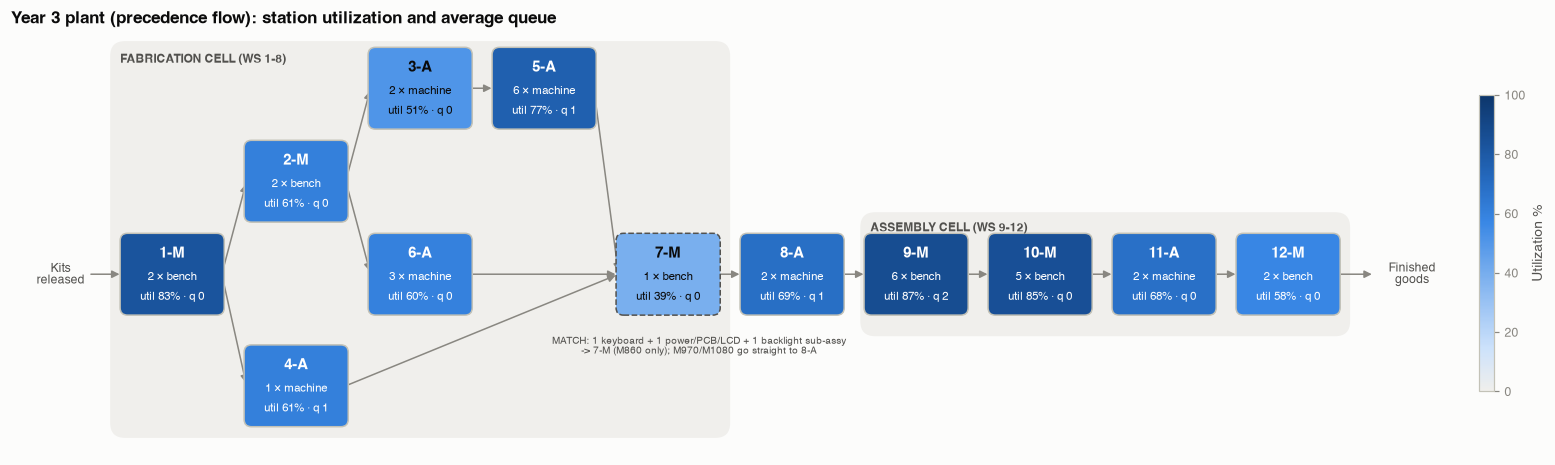

In [2]:
res = run(sc)
assert all(value == 0 for key, value in res.checks.items() if "must be 0" in key), res.checks
assert res.checks["max operator utilization (<= 1)"] <= 1 + 1e-9
assert (res.stations["Gate-blocked %"] == 0).all()
print("Accounting and operator checks:", res.checks)
P.plot_block_diagram(res); plt.show()


## 3. Throughput by product versus demand

Read each product separately. With the heijunka sequence, each model's kits arrive in proportion to its own kit volume, so each model's weekly output should sit close to its own dashed demand line. The remaining week-to-week variation comes from scrap, breakdowns, and maintenance, not from the release.

,Finished,Per week,Demand per week,% of demand,Avg flow time (hr),P90 flow time (hr)
Model,,,,,,
M860,"10,273.000","1,284.125","1,277.540",1.005,0.416,0.620
M970,"8,847.000","1,105.875","1,105.920",1.000,0.587,0.791
M1080,"9,833.000","1,229.125","1,230.320",0.999,0.643,0.851
Total,"28,953.000","3,619.125","3,613.780",1.001,0.546,0.777


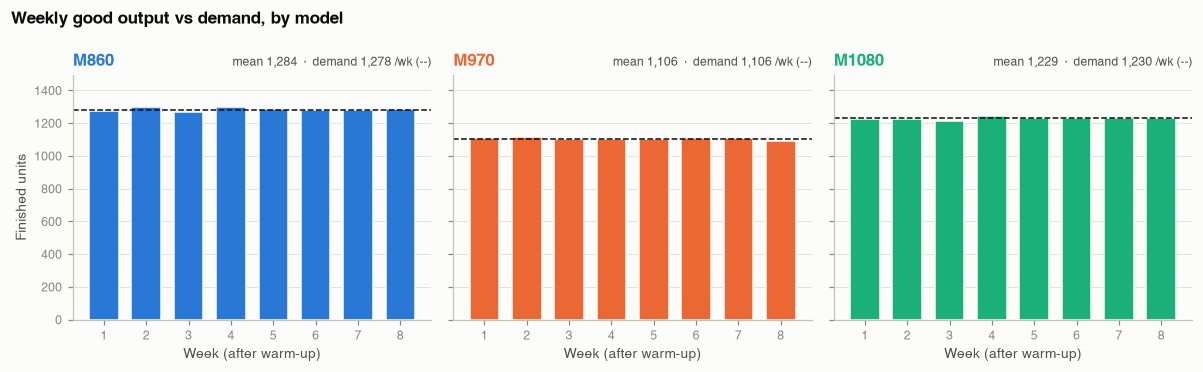

In [3]:
display(res.throughput)
P.plot_throughput(res); plt.show()


## 4. Queues, WIP, and matching

Daily station bars show waiting units by product; the detailed lines show the time pattern. No lot gates are used in this policy.

**Waiting at the match** is the component buffer after fabrication branches 4-A, 5-A, and 6-A. It is separate from station 7. One keyboard, one power/PCB/LCD, and one backlight subassembly from the same product lot must be available before an assembly moves to 7-M (M860) or directly to 8-A (M970/M1080). Waiting components count as WIP and occupy no operators or machines.

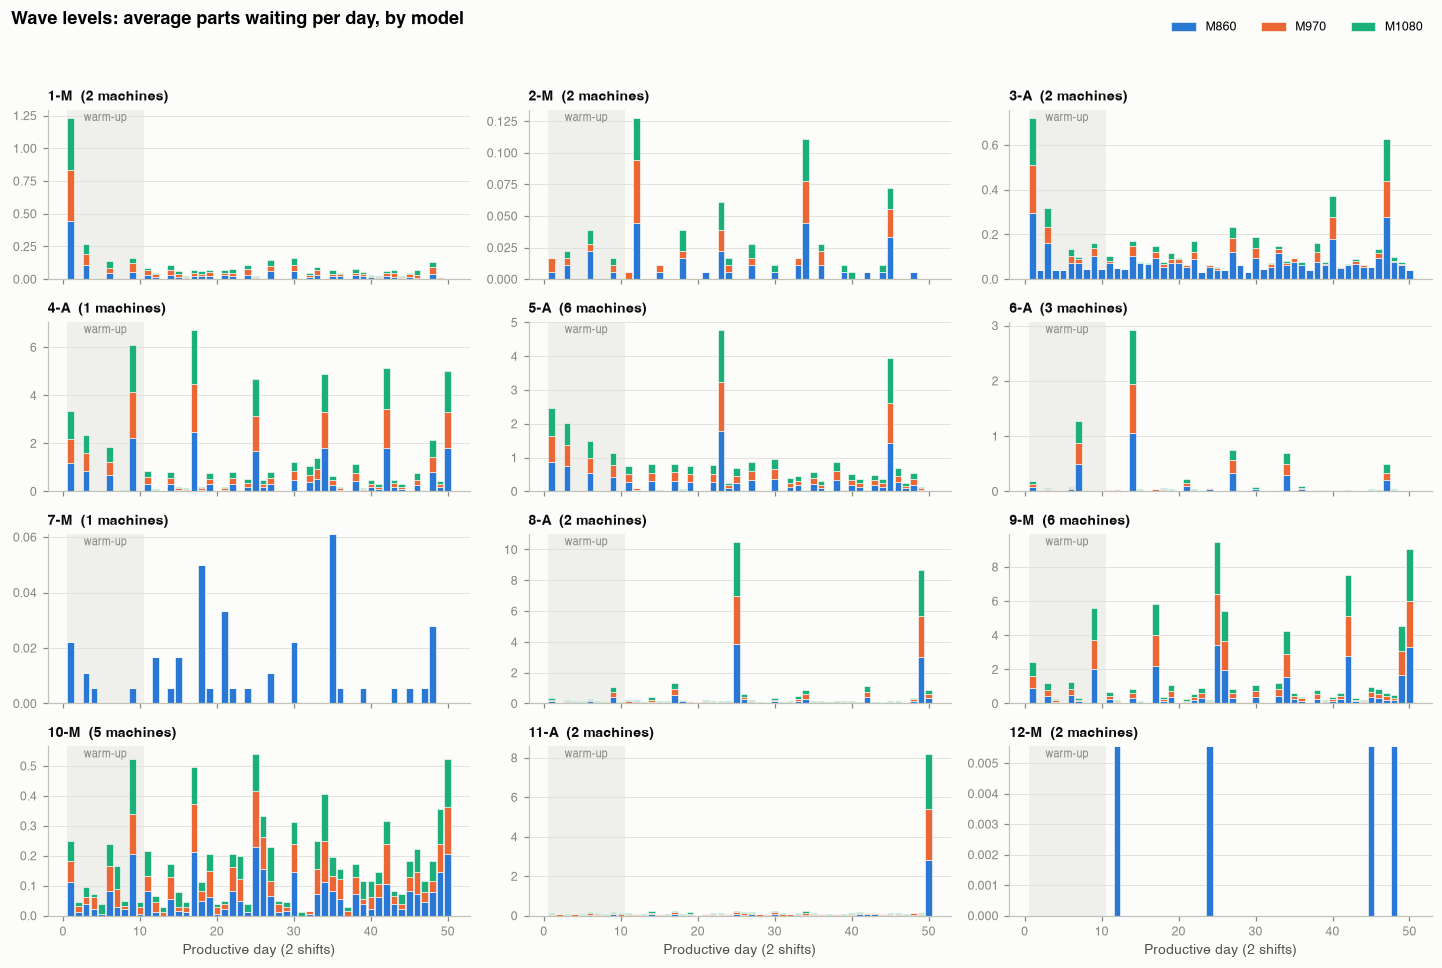

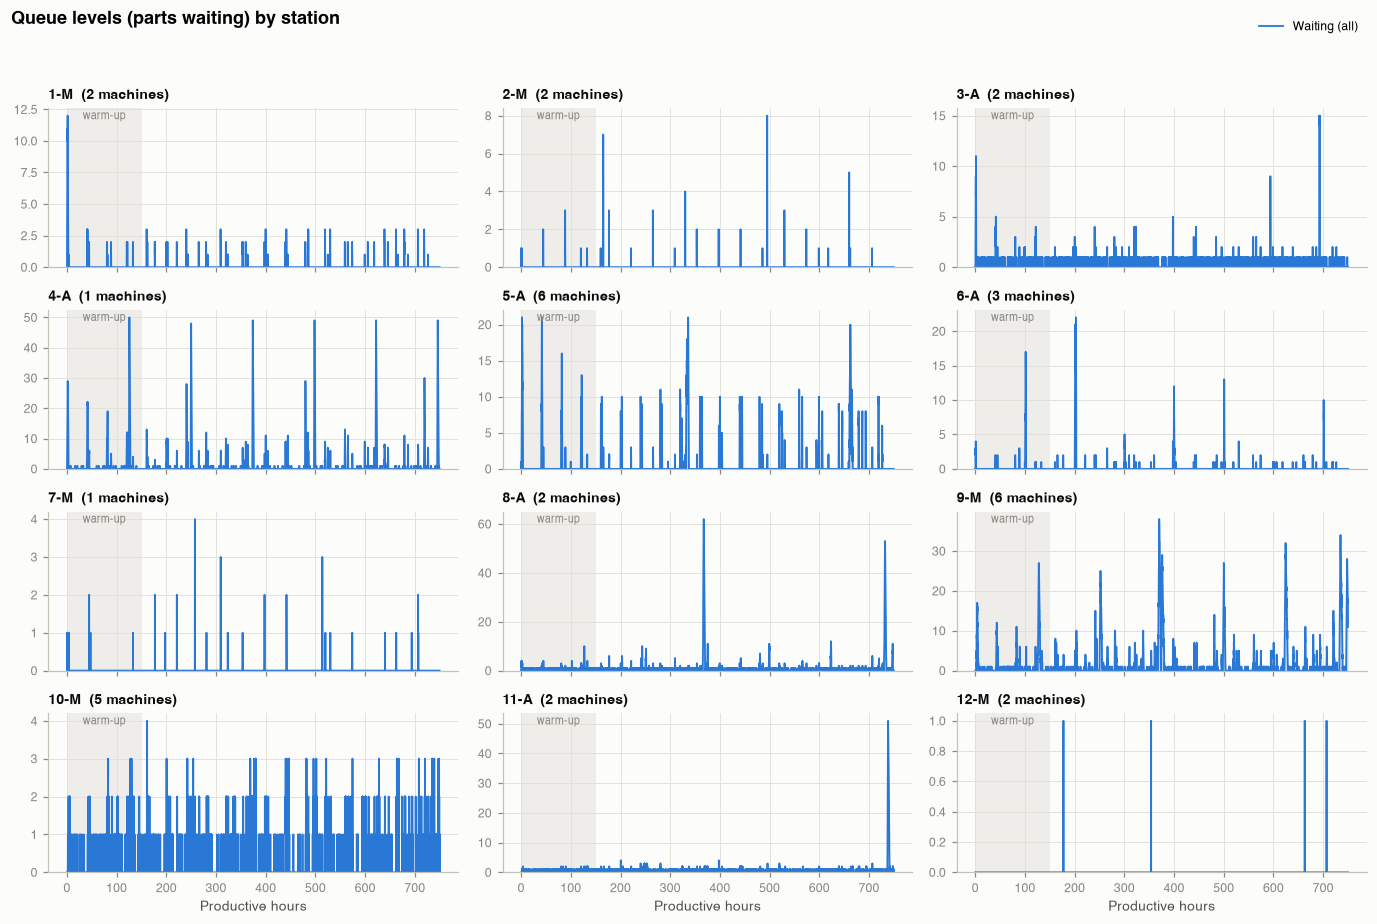

In [4]:
P.plot_wave_levels(res); plt.show()
P.plot_queue_lines(res, gated=False); plt.show()


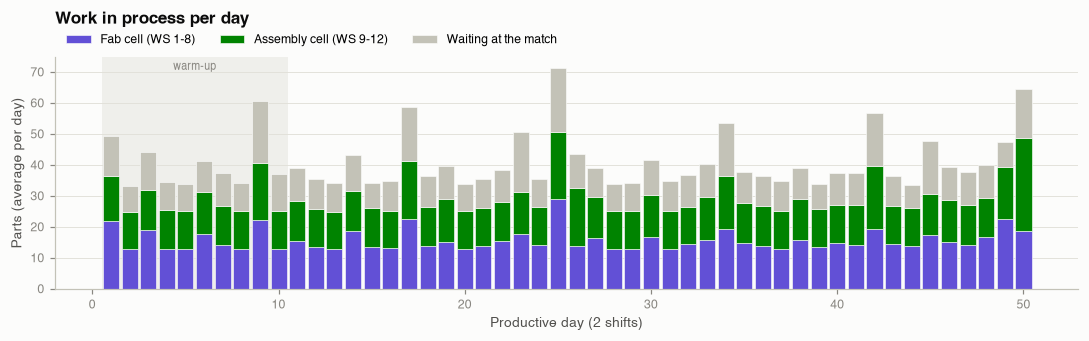

WIP near measurement start/end: 35 / 47 items
Net change: 12 items
Time-average WIP: 40.9 component/assembly items


In [5]:
P.plot_wip(res); plt.show()
window = res.trace[res.trace.t >= sc.warmup_min]
print(f"WIP near measurement start/end: {window.iloc[0]['WIP']:,.0f} / {window.iloc[-1]['WIP']:,.0f} items")
print(f"Net change: {window.iloc[-1]['WIP'] - window.iloc[0]['WIP']:,.0f} items")
print(f"Time-average WIP: {res.kpis['WIP|Average WIP (parts)']:,.1f} component/assembly items")


## 5. Station utilization and capacity

Utilization includes processing plus setup. The historical Phase 1 comparison and processing-only capacity estimates are reference values based on the original planned mix; the heijunka sequence uses that same planned kit mix. Capacity bars exclude setup, operator waiting, and downtime.

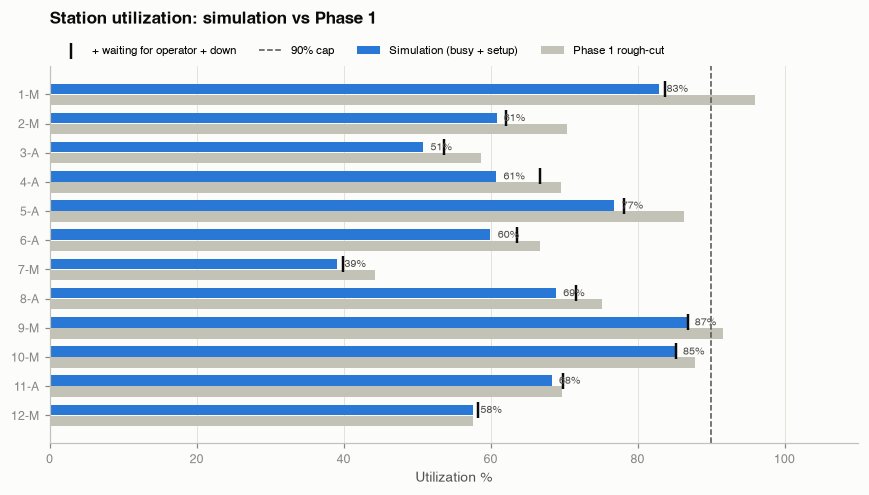

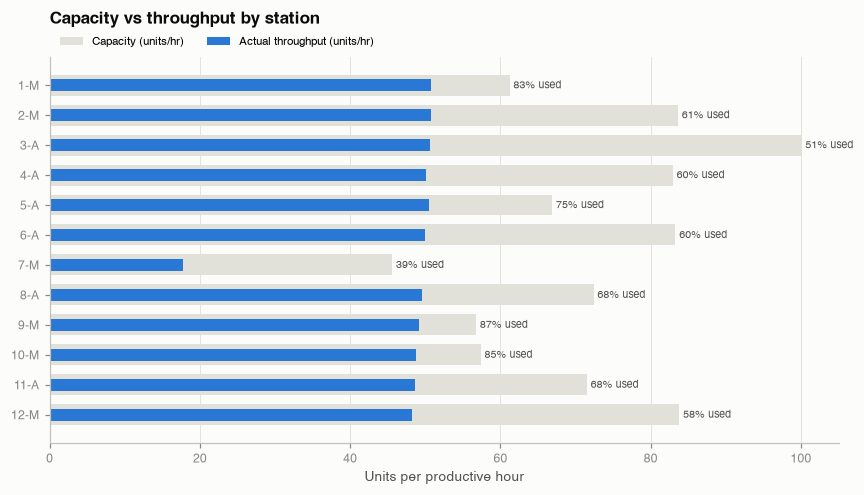

,Cell,Machines,Utilization,Busy %,Setup %,WaitOp %,Down %,Idle %,Capacity (units/hr),Throughput (units/hr),Avg queue,Max queue,Avg wait (min),Wait for operator (min/part),Group setups
Station,,,,,,,,,,,,,,,
1-M,Fab,2,0.830,0.828,0.002,0.008,0.000,0.163,61.230,50.703,0.049,4.000,0.058,0.019,0
2-M,Fab,2,0.608,0.606,0.002,0.012,0.001,0.379,83.642,50.703,0.015,8.000,0.018,0.027,0
3-A,Fab,2,0.508,0.506,0.003,0.022,0.005,0.464,100.091,50.612,0.110,16.000,0.130,0.053,0
4-A,Fab,1,0.608,0.604,0.003,0.049,0.010,0.333,82.950,50.123,1.074,51.000,1.285,0.059,0
5-A,Fab,6,0.768,0.754,0.015,0.006,0.007,0.219,66.894,50.437,0.539,21.000,0.642,0.041,0
6-A,Fab,3,0.600,0.599,0.001,0.026,0.011,0.364,83.299,49.932,0.148,22.000,0.178,0.094,0
7-M,Fab,1,0.391,0.390,0.001,0.007,0.001,0.601,45.605,17.785,0.008,4.000,0.027,0.022,0
8-A,Fab,2,0.689,0.685,0.004,0.022,0.006,0.284,72.403,49.593,0.743,62.000,0.899,0.052,0
9-M,Asm,6,0.868,0.867,0.000,0.001,0.000,0.131,56.767,49.185,1.526,39.000,1.862,0.005,0


In [6]:
P.plot_utilization(res); plt.show()
P.plot_capacity(res); plt.show()
display(res.stations[["Cell", "Machines", "Utilization", "Busy %", "Setup %", "WaitOp %", "Down %", "Idle %",
                      "Capacity (units/hr)", "Throughput (units/hr)", "Avg queue", "Max queue", "Avg wait (min)",
                      "Wait for operator (min/part)", "Group setups"]])


## 6. Machine states and individual machines

The station chart aggregates parallel machines. The heatmap and machine chart expose uneven loading. During a group setup, all participating machines are in Setup; while the setup team is being acquired, they are in Waiting for operator.

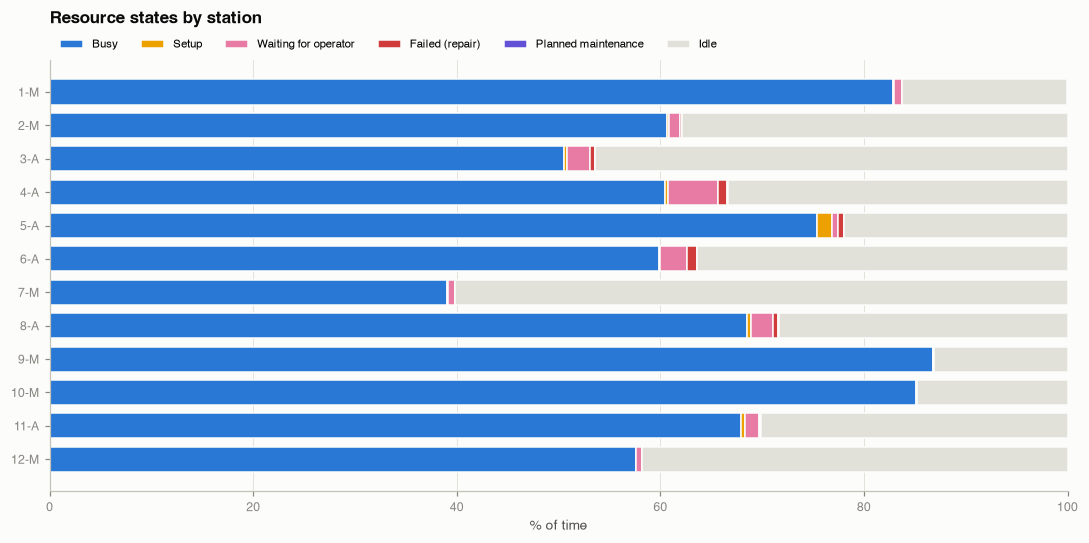

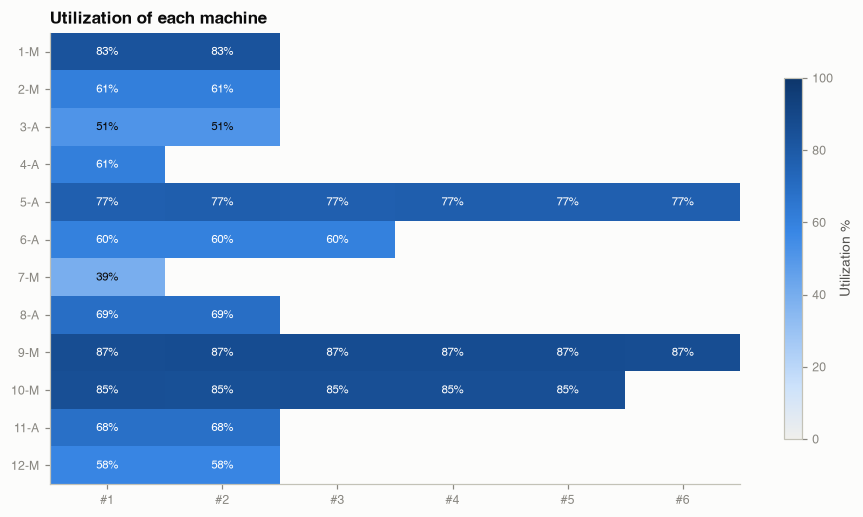

In [7]:
P.plot_machine_states(res, by="station"); plt.show()
P.plot_machine_heatmap(res); plt.show()


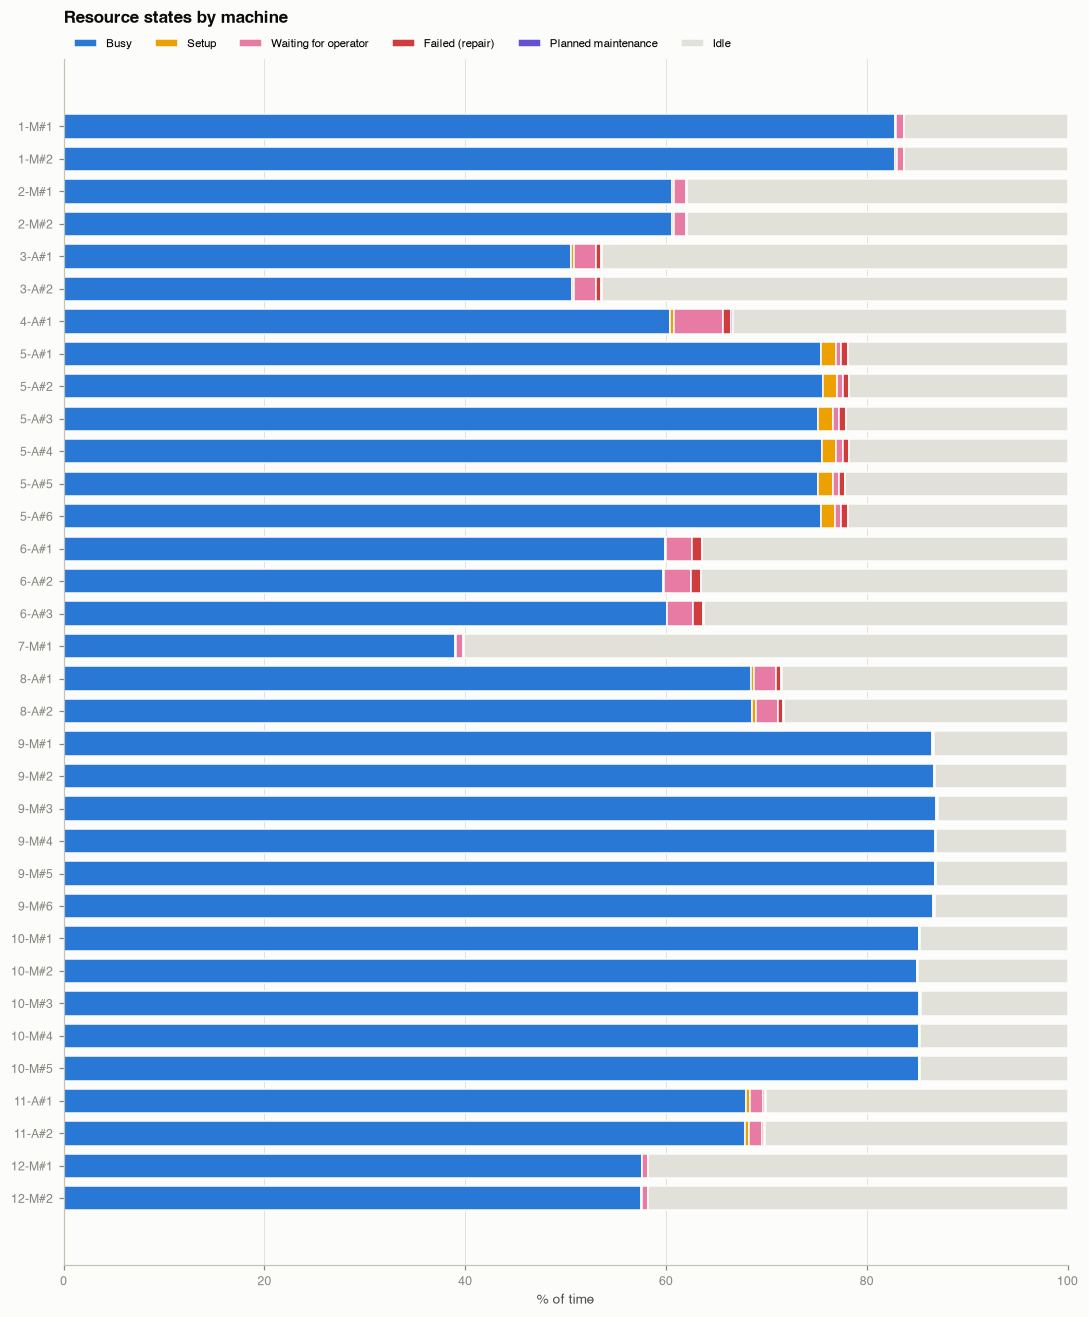

In [8]:
P.plot_machine_states(res, by="machine"); plt.show()
# display(res.machines)


## 7. Operator workload and activity

Setup crews draw from the same cell operator pools used for normal processing. Daily busy-operator plots show demand against staffing. Gantt charts show the first four logged hours after warm-up, with colors indicating station assignment; simultaneous team assignments appear on multiple operator rows.

,Crew per shift,Scheduled labor-hr,Busy labor-hr,Idle labor-hr,Avg busy,Peak busy,Utilization,Avg WIP in cell,Avg wait for operator (min/part),Avg wait for machine (min/part)
Cell,,,,,,,,,,
Fab,7,"4,200.000","3,246.881",953.119,5.411,7.000,0.773,15.660,0.048,0.436
Asm,13,"7,800.000","6,586.867","1,213.133",10.978,13.000,0.844,14.065,0.014,0.626


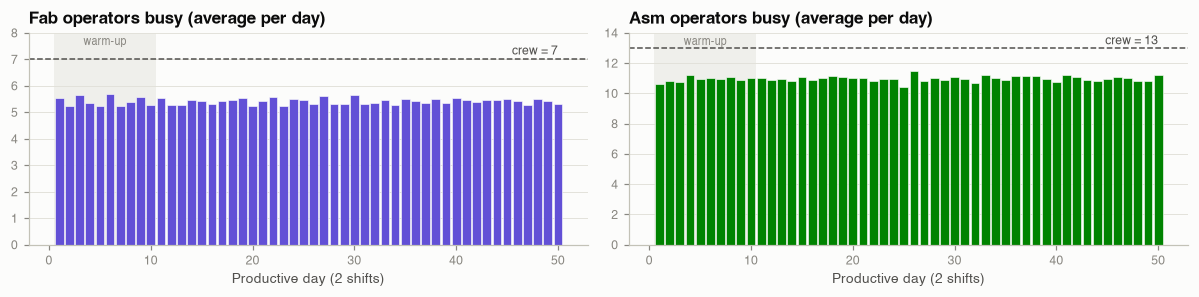

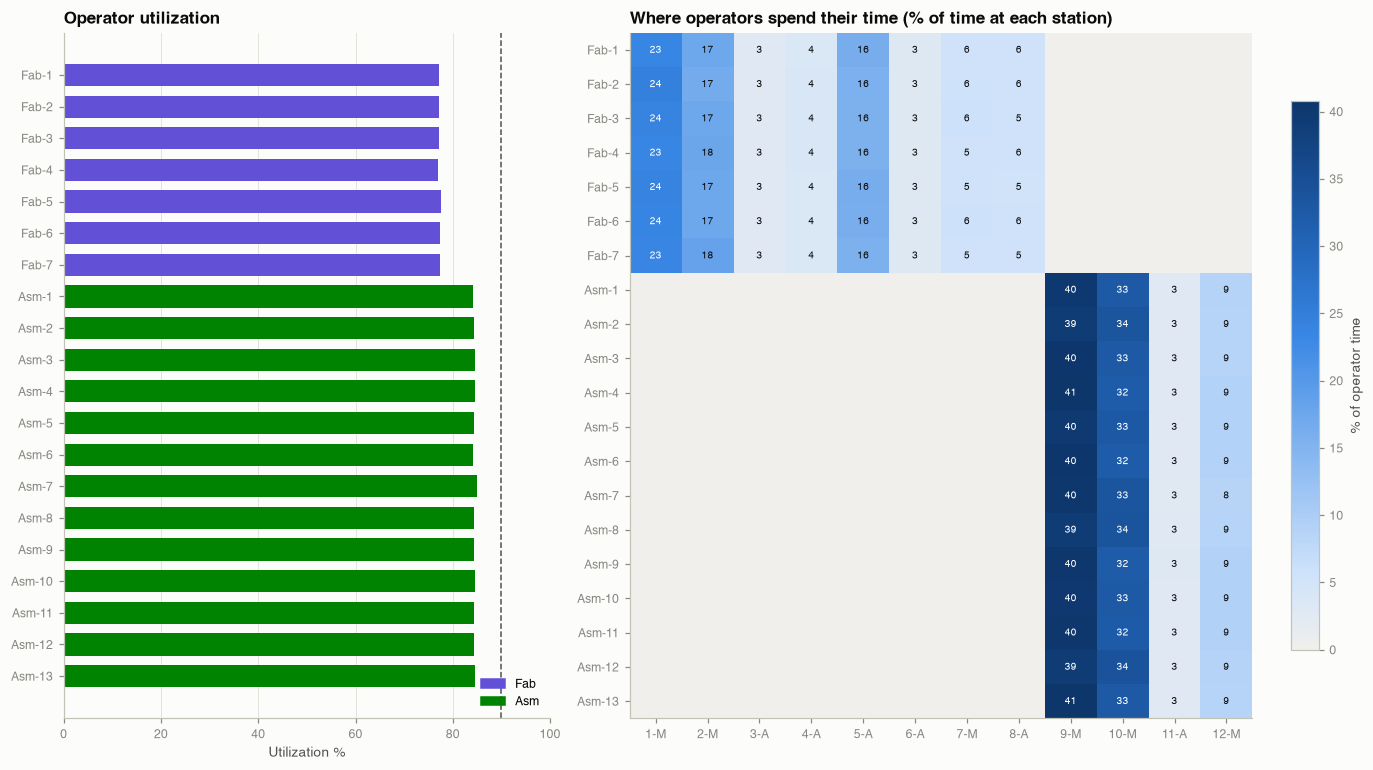

,Cell,Busy (hr),Utilization,Main station,1-M hr,2-M hr,3-A hr,4-A hr,5-A hr,6-A hr,7-M hr,8-A hr,9-M hr,10-M hr,11-A hr,12-M hr
Fab-1,Fab,463.100,0.772,1-M,140.000,104.000,16.800,21.500,96.800,17.600,33.100,33.200,0.000,0.000,0.000,0.000
Fab-2,Fab,463.371,0.772,1-M,146.300,99.800,16.400,22.100,93.800,17.800,34.000,33.300,0.000,0.000,0.000,0.000
Fab-3,Fab,463.585,0.773,1-M,143.500,103.300,16.300,22.100,93.200,18.100,34.600,32.500,0.000,0.000,0.000,0.000
Fab-4,Fab,462.171,0.770,1-M,139.500,105.600,16.800,22.100,93.600,18.300,32.800,33.400,0.000,0.000,0.000,0.000
Fab-5,Fab,465.420,0.776,1-M,144.200,104.100,16.400,21.100,96.800,17.500,32.900,32.400,0.000,0.000,0.000,0.000
Fab-6,Fab,464.393,0.774,1-M,141.400,103.400,16.700,21.500,95.900,17.500,34.600,33.400,0.000,0.000,0.000,0.000
Fab-7,Fab,464.811,0.775,1-M,140.600,109.500,16.400,21.700,93.500,17.600,32.600,32.800,0.000,0.000,0.000,0.000
Asm-1,Asm,505.181,0.842,9-M,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,239.700,195.400,16.800,53.300
Asm-2,Asm,505.658,0.843,9-M,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,235.100,201.400,16.700,52.500
Asm-3,Asm,506.921,0.845,9-M,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,242.700,195.800,16.400,52.100


In [9]:
display(res.cells)
P.plot_operators_busy(res); plt.show()
P.plot_operators(res); plt.show()
display(res.operators.join((res.op_station / 60).round(1).add_suffix(" hr")))


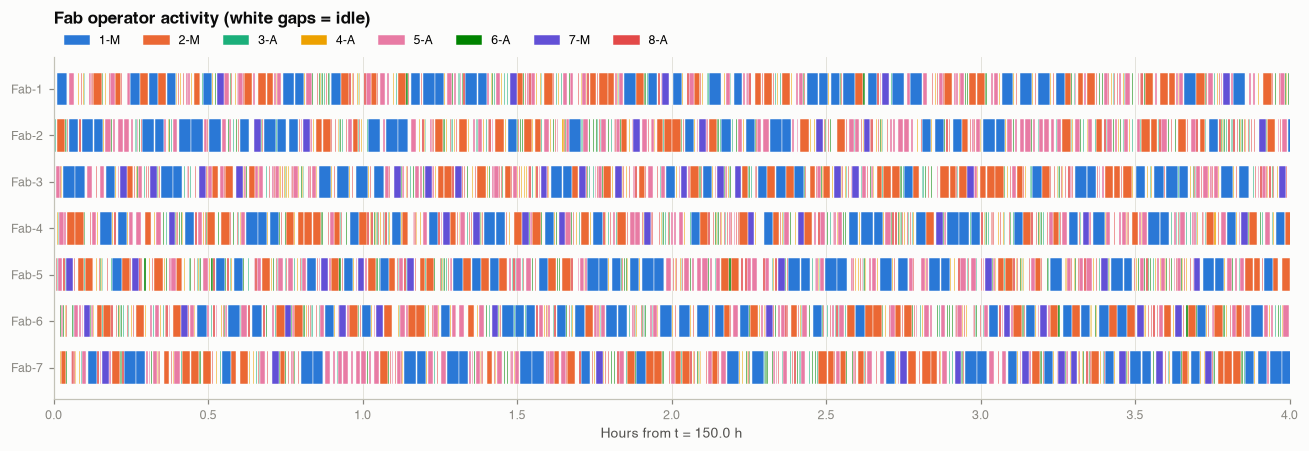

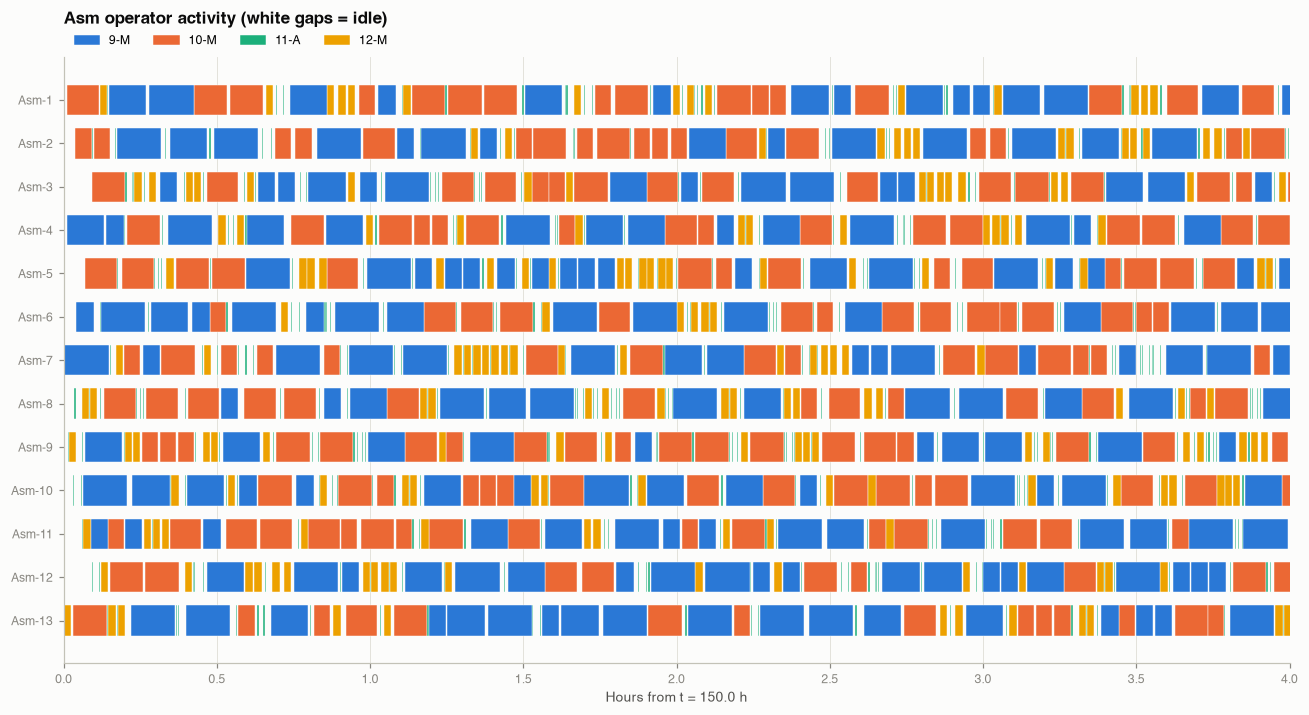

In [10]:
P.plot_operator_gantt(res, cell="Fab", hours=4); plt.show()
P.plot_operator_gantt(res, cell="Asm", hours=4); plt.show()


## 8. Station-group setups and team labor

Group setups count whole-station events during the measurement window. Machine setups count each participating machine: one event at 5-A contributes six machine setups. The event table and crew chart use the first logged week after warm-up; the event-count chart uses the complete eight-week measurement period.

,Station,Lot,Model,Start,End,Crew,Elapsed min,Operator min
0,1-M,15,M860,"10,589.976","10,594.142",1,4.167,4.167
1,1-M,15,M860,"10,595.297","10,599.464",1,4.167,4.167
2,1-M,18,M860,"13,235.990","13,240.157",1,4.167,4.167
3,1-M,18,M860,"13,241.312","13,245.478",1,4.167,4.167
4,10-M,15,M860,"10,626.185","10,627.574",1,1.389,1.389
5,10-M,15,M860,"10,627.404","10,628.793",1,1.389,1.389
6,10-M,15,M860,"10,629.883","10,631.272",1,1.389,1.389
7,10-M,15,M860,"10,633.255","10,634.644",1,1.389,1.389
8,10-M,15,M860,"10,638.126","10,639.515",1,1.389,1.389
9,10-M,18,M860,"13,273.939","13,275.327",1,1.389,1.389


,Machines,Group setups,Setups,Setup %,WaitOp %
Station,,,,,
1-M,2,0,26,0.002,0.008
2-M,2,0,26,0.002,0.012
3-A,2,0,86,0.003,0.022
4-A,1,0,43,0.003,0.049
5-A,6,0,258,0.015,0.006
6-A,3,0,39,0.001,0.026
7-M,1,0,13,0.001,0.007
8-A,2,0,86,0.004,0.022
9-M,6,0,78,0.000,0.001


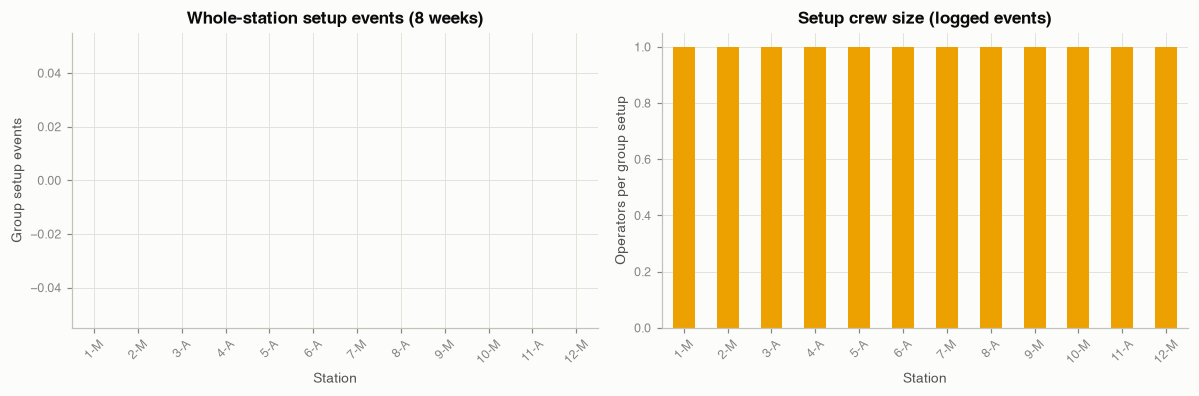

In [11]:
setup_tasks = res.op_log[res.op_log.Task == "setup"].copy()
events = pd.DataFrame()
if not setup_tasks.empty:
    events = setup_tasks.groupby(["Station", "Lot", "Model", "Start", "End"]).agg(Crew=("Operator", "nunique")).reset_index()
    events["Elapsed min"] = events.End - events.Start
    events["Operator min"] = events["Elapsed min"] * events.Crew
    display(events.head(25))
display(res.stations[["Machines", "Group setups", "Setups", "Setup %", "WaitOp %"]])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
res.stations["Group setups"].reindex(STATIONS).plot.bar(ax=axes[0], color="#2a78d6", rot=45)
axes[0].set_title("Whole-station setup events (8 weeks)")
axes[0].set_ylabel("Group setup events")
if not events.empty:
    observed = events.groupby("Station").Crew.mean().reindex(STATIONS)
    observed.plot.bar(ax=axes[1], color="#eda100", rot=45)
axes[1].set_title("Setup crew size (logged events)")
axes[1].set_ylabel("Operators per group setup")
fig.tight_layout(); plt.show()


## 9. Scrap, spare components, and lot completion

Scrap is measured per entity: a kit, component, or assembled display. Unneeded branch outputs are counted as spare; unmatched components left when their accounting group closes are counted separately. EOQ identifiers are accounting and matching groups, not station processing restrictions.

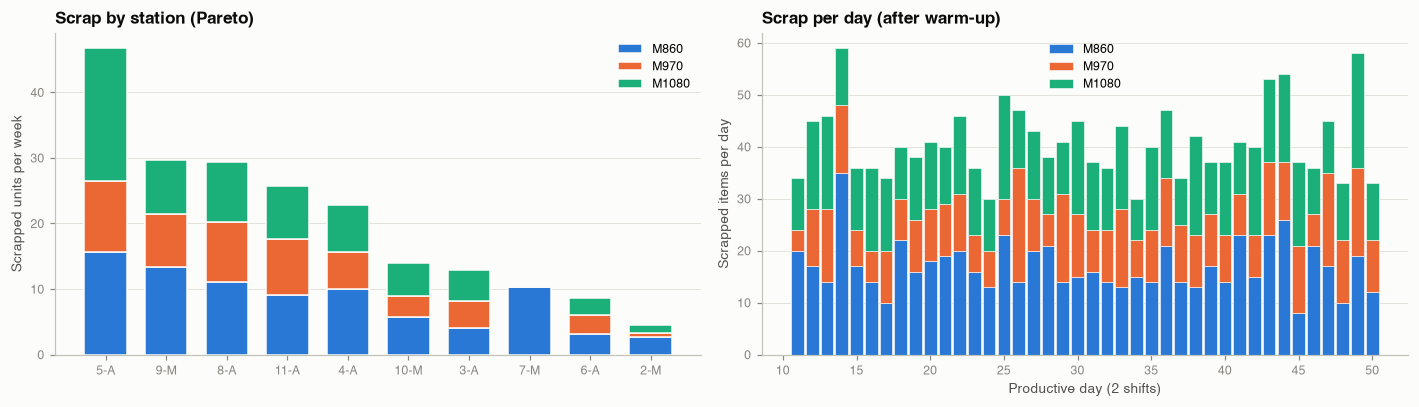

Units per week  Invested_min per week  Labor_dollars per week
Station Item                         Model                                                               
10-M    Display assembly             M1080           5.100                206.700                  41.200
                                     M860            5.800                127.400                  29.000
                                     M970            3.100                106.200                  22.200
11-A    Display assembly             M1080           8.100                342.100                  65.900
                                     M860            9.100                217.500                  46.500
                                     M970            8.500                302.400                  60.900
2-M     LCD/PCB set                  M1080           1.200                  4.900                   1.300
                                     M860            2.800                  7.900                   2.300
                                     M970            0.500                  1.700                   0.400
3-A     Power strip/PCB/LCD sub-assy M1080           4.800                 26.700                   5.200
                                     M860            4.100                 14.200                   3.600
                                     M970            4.000                 19.200                   3.700
4-A     Keyboard sub-assy            M1080           7.200                 21.500                   4.800
                                     M860           10.000                 27.100                   5.500
                                     M970            5.600                 13.100                   2.900
5-A     Power strip/PCB/LCD sub-assy M1080          20.200                260.700                  30.300
                                     M860           15.600                 95.900                  18.300
                                     M970           10.900                122.500                  14.100
6-A     Backlight/sensor sub-assy    M1080           2.600                 19.000                   2.900
                                     M860            3.100                 12.900                   2.500
                                     M970            2.900                 15.400                   2.700
7-M     Display assembly             M860           10.400                148.200                  29.600
8-A     Display assembly             M1080           9.100                229.600                  31.800
                                     M860           11.100                173.900                  33.200
                                     M970            9.100                187.200                  26.200
9-M     Display assembly             M1080           8.200                278.900                  49.200
                                     M860           13.400                254.200                  53.400
                                     M970            8.100                225.800                  41.100

,EOQ,Kits,Finished,Finished / EOQ,Short of EOQ,Scrapped,Spare,Unmatched,Yield (finished / kits),Planned yield,Lot flow time (hr)
Model,,,,,,,,,,,
M1080,655.000,685.000,654.222,0.999,1.667,35.444,24.000,0.000,0.955,0.957,40.336
M860,754.000,801.000,752.062,0.997,3.750,54.812,21.625,5.438,0.939,0.942,44.287
M970,596.000,620.000,595.167,0.999,1.944,28.389,11.556,3.167,0.960,0.961,40.660


In [12]:
P.plot_scrap(res); plt.show()
weeks = res.T / 4500
scr = res.scrap.groupby(["Station", "Item", "Model"]).agg(Units=("Part", "count"),
    Invested_min=("Invested min", "sum"), Labor_dollars=("Labor $", "sum"))
display((scr / weeks).round(1).rename(columns=lambda c: c + " per week"))
lots = res.lots.dropna(subset=["Done"])
display(lots.groupby("Model")[["EOQ", "Kits", "Finished", "Finished / EOQ", "Short of EOQ", "Scrapped", "Spare",
    "Unmatched", "Yield (finished / kits)", "Planned yield", "Lot flow time (hr)"]].mean())


## 10. Individual-display flow time (SPC)

Flow time starts at the actual arrival of the oldest constituent kit and ends at finished-display departure. It includes setup, queues, matching, downtime, and processing. It is not the same as whole-lot completion time.

Each model gets an **individuals (I) control chart** with one point per finished display, in completion order. The centre line is the mean flow time. σ̂ = MR̄/1.128, where MR̄ is the average moving range between consecutive displays of the same model, and the limits are CL ± kσ̂. The shaded bands are the 1σ and 2σ zones. The y axis is logarithmic so the control band stays readable next to the long tail, but the limits and rules use raw hours.

Out-of-control signals use the **Western Electric (Shewhart) rules**:

1. One point beyond 3σ
2. Two of three consecutive points beyond 2σ on the same side
3. Four of five consecutive points beyond 1σ on the same side
4. Eight consecutive points on one side of the centre line

Interpretation: sub-assemblies of the same model are interchangeable, so they are matched oldest-first from one pool per model, not per lot. With kit pull, keyboards and backlights are only built when their branch is behind the power-strip branch. This keeps the pooled stock (and therefore match wait) small. Consecutive displays still ride the same queues and have nearly identical flow times, so MR̄ (and σ̂) is very small and most points trip a run rule. That is the textbook result for strongly autocorrelated data. Read the signals as "flow time moves in waves driven by setups, downtime and queue build-up", not as individual bad displays.

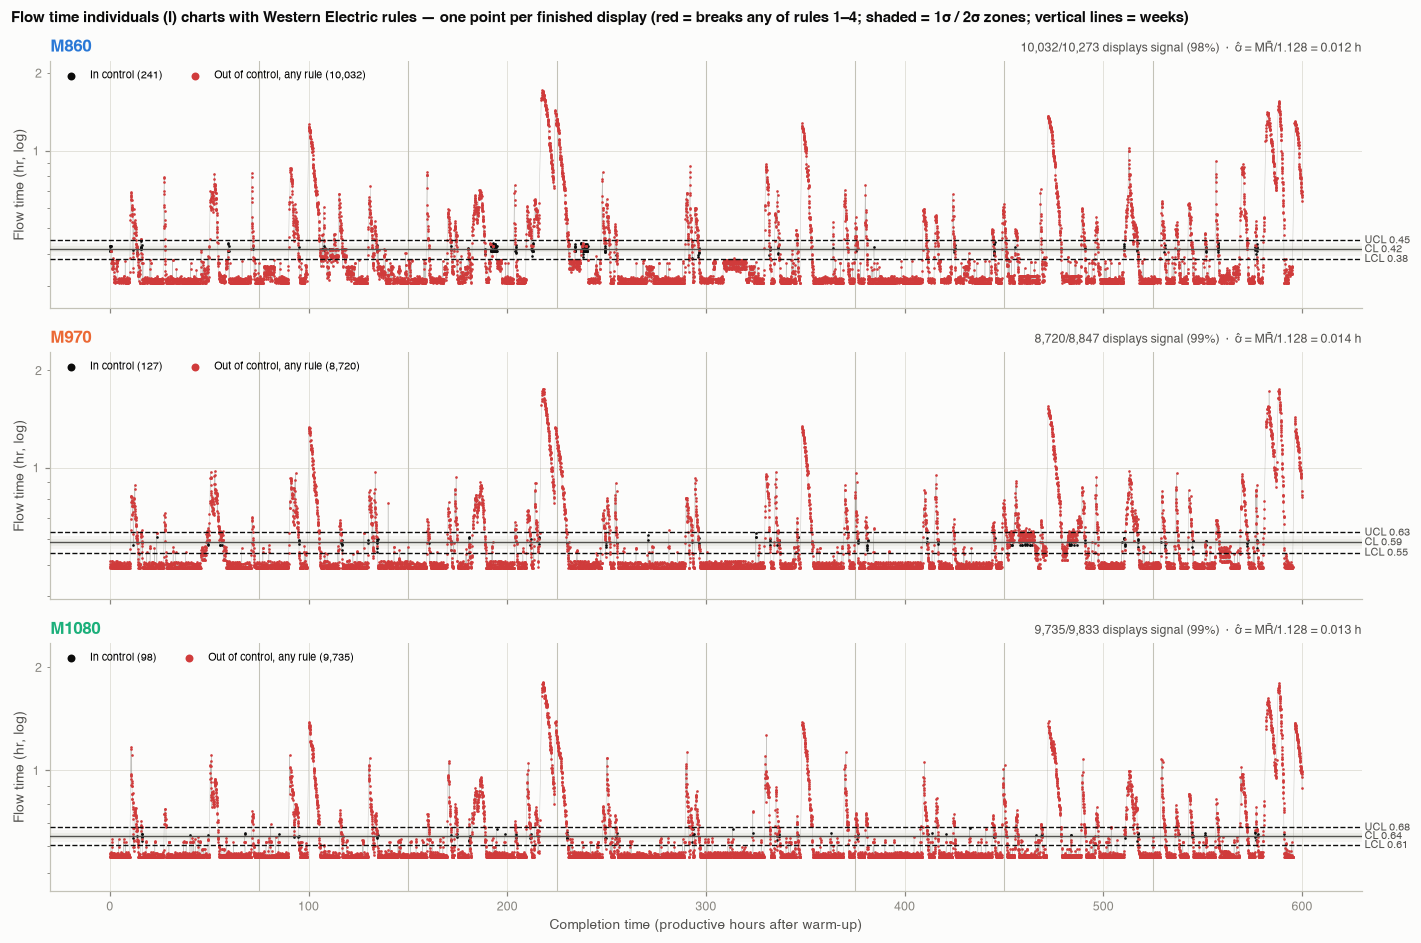

,Displays,CL (hr),σ̂ = MR̄/1.128 (hr),UCL (hr),LCL (hr),Rule 1: 1 point beyond 3σ,Rule 2: 2 of 3 beyond 2σ (same side),Rule 3: 4 of 5 beyond 1σ (same side),Rule 4: 8 in a row on one side of CL,Any signal
Model,,,,,,,,,,
M860,10273,0.416,0.012,0.451,0.381,9451,9662,9855,9942,10032
M970,8847,0.587,0.014,0.629,0.545,7826,8148,8461,8665,8720
M1080,9833,0.643,0.013,0.681,0.605,9009,9309,9566,9665,9735


,Avg flow time (hr),P90 flow time (hr)
Model,,
M860,0.416,0.620
M970,0.587,0.791
M1080,0.643,0.851
Total,0.546,0.777


In [13]:
P.plot_flow_time_spc(res); plt.show()
spc = P.flow_time_spc(res)
rule_cols = [f"Rule {r}" for r in P.WE_RULES]
display(spc.groupby("Model", sort=False)
           .agg(Displays=("Part", "count"), **{"CL (hr)": ("CL", "first"), "σ̂ = MR̄/1.128 (hr)": ("sigma", "first"),
                "UCL (hr)": ("+3σ", "first"), "LCL (hr)": ("-3σ", "first")},
                **{c: (c, "sum") for c in rule_cols}, **{"Any signal": ("Signal", "sum")})
           .reindex(MODELS)
           .rename(columns={f"Rule {r}": f"Rule {r}: {t}" for r, t in P.WE_RULES.items()}))
display(res.throughput[["Avg flow time (hr)", "P90 flow time (hr)"]])


## 11. Replications and policy comparisons

Six policies, each with ten replications (seeds 1–10): your partner's four from `phase2_assumptions_simulation.ipynb` (continuous product runs, cyclic with per-machine changeovers, cyclic + workcell with and without SPC) plus heijunka + workcell with and without SPC. The no-SPC references retain original scrap probabilities. SPC reduces planned scrap allowances and therefore input kit requirements and arrival frequency; demand targets are unchanged. Check the per-model table: cyclic meets total demand while under-building M860 and over-building M970. Reported half-widths are 95% confidence intervals for the mean.

In [14]:
# cyclic_spc = get_scenario(YEAR, release_mode="cyclic", setup_scope="workcell", setup_crew=SETUP_CREW,
#                           scrap_scale=SPC_SCRAP_SCALE)
# policies = {
#     "Continuous product runs": get_scenario(YEAR, release_mode="continuous"),
#     "Unit rotation: machine changeovers": get_scenario(YEAR, release_mode="cyclic"),
#     "Unit rotation: assumptions (no SPC)": replace(cyclic_spc, scrap_scale=1.0),
#     "Unit rotation: assumptions": cyclic_spc,
#     "Heijunka + workcell (no SPC)": replace(sc, scrap_scale=1.0),
#     "Heijunka + workcell": sc,
# }
# summaries = {}
# for name, scenario in policies.items():
#     print("Running:", name, flush=True)
#     _, summaries[name] = run_replications(scenario, n=N_REPS, n_jobs=N_JOBS)
# keys = [
#     ("WIP", "Average WIP (parts)"), ("WIP", "Ending WIP (parts)"),
#     ("Throughput", "Total per week"), ("Throughput", "% of demand"),
#     *[("Throughput", f"{model} per week") for model in MODELS],
#     *[("Flow time (hr)", model) for model in MODELS],
#     ("Scrap", "Items scrapped per week"),
#     ("Operators", "Fab utilization"), ("Operators", "Asm utilization"),
# ]
# comparison = pd.concat([summary.loc[keys, "Average"].rename(name) for name, summary in summaries.items()], axis=1)
# display(comparison)

# # Each model's weekly output as a share of its own weekly demand
# demand_wk = {m: sc.demand[m] / 50 for m in MODELS}
# by_model = pd.DataFrame({name: {m: s.loc[("Throughput", f"{m} per week"), "Average"] / demand_wk[m]
#                                 for m in MODELS} for name, s in summaries.items()})
# display(by_model.style.format("{:.1%}").set_caption("Output as % of each model's demand"))

# assumptions_summary = summaries["Heijunka + workcell"]
# display(assumptions_summary.loc[keys, ["Average", "Half Width", "Minimum", "Maximum"]])
# comparison.to_csv("heijunka_comparison.csv")

Running: Continuous product runs
Running: Unit rotation: machine changeovers
Running: Unit rotation: assumptions (no SPC)
Running: Unit rotation: assumptions
Running: Heijunka + workcell (no SPC)
Running: Heijunka + workcell


Process SpawnProcess-47:
Process SpawnProcess-42:
Process SpawnProcess-43:
Process SpawnProcess-45:
Process SpawnProcess-46:
Process SpawnProcess-41:
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/multiprocessing/process.py", line 313, in _bootstrap
    self.run()
    ~~~~~~~~^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/multiprocessing/process.py", line 108, in run
    self._target(*self._args, **self._kwargs)
    ~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/multiprocessing/process.py", line 313, in _bootstrap
    self.run()
    ~~~~~~~~^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/multiprocessing/process.py", line 108, i

KeyboardInterrupt: 

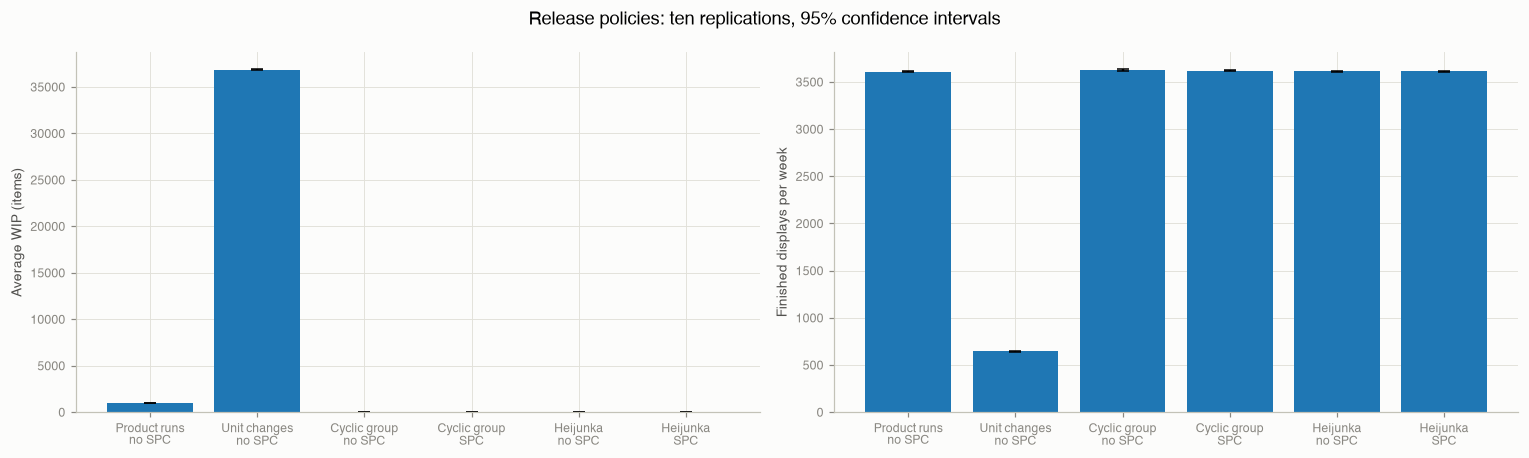

In [ ]:
# fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
# labels = ["Product runs\nno SPC", "Unit changes\nno SPC", "Cyclic group\nno SPC", "Cyclic group\nSPC",
#           "Heijunka\nno SPC", "Heijunka\nSPC"]
# for ax, key, label in zip(axes, [("WIP", "Average WIP (parts)"), ("Throughput", "Total per week")],
#                          ["Average WIP (items)", "Finished displays per week"]):
#     means = [summary.loc[key, "Average"] for summary in summaries.values()]
#     errors = [summary.loc[key, "Half Width"] for summary in summaries.values()]
#     ax.bar(labels, means, yerr=errors, capsize=4)
#     ax.tick_params(axis="x", labelsize=8)
#     ax.set_ylabel(label)
# fig.suptitle("Release policies: ten replications, 95% confidence intervals")
# fig.tight_layout(); plt.show()

## 12. Bottlenecks across replications

Station utilization and average queues are averaged across the heijunka + workcell (SPC) replications. High utilization and persistent queues identify constraints; machine Setup and Waiting for operator states explain capacity losses.

,Avg utilization (10 reps),Avg queue (10 reps),Machines,Setup %,WaitOp %,Group setups
Statistic,,,,,,
9-M,0.867,2.051,6,0.000,0.001,13
10-M,0.851,0.221,5,0.001,0.001,13
1-M,0.830,0.342,2,0.002,0.014,13
5-A,0.768,0.931,6,0.015,0.006,43
8-A,0.689,0.952,2,0.004,0.023,43
11-A,0.682,0.320,2,0.004,0.018,43
2-M,0.608,0.037,2,0.002,0.018,13
4-A,0.607,0.838,1,0.003,0.053,43
6-A,0.600,0.213,3,0.001,0.030,13


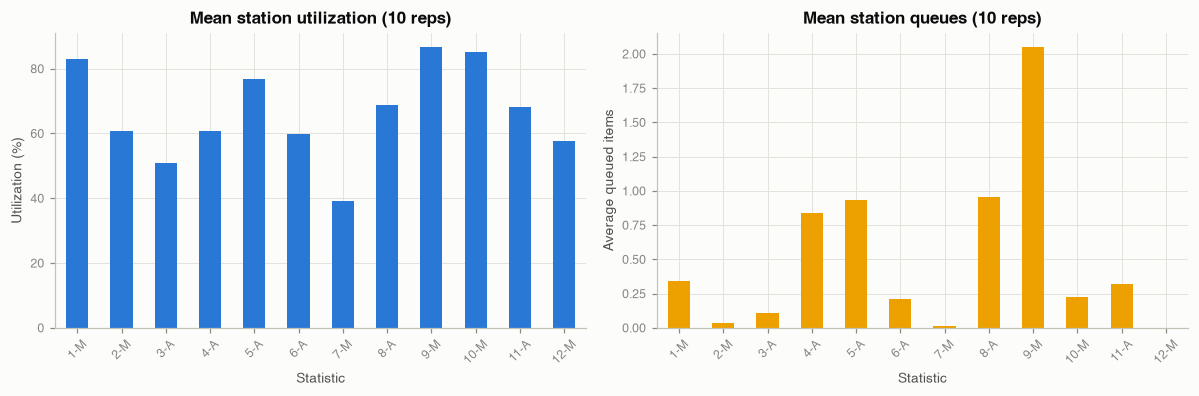

In [ ]:
# summary = assumptions_summary
# avg_util = summary.xs("Station utilization").Average.rename("Avg utilization (10 reps)")
# avg_q = summary.xs("Avg queue").Average.rename("Avg queue (10 reps)")
# bottlenecks = pd.concat([avg_util, avg_q], axis=1).join(res.stations[["Machines", "Setup %", "WaitOp %", "Group setups"]])
# display(bottlenecks.sort_values("Avg utilization (10 reps)", ascending=False))
# fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
# avg_util.reindex(STATIONS).mul(100).plot.bar(ax=axes[0], color="#2a78d6", rot=45)
# axes[0].set_ylabel("Utilization (%)")
# axes[0].set_title("Mean station utilization (10 reps)")
# avg_q.reindex(STATIONS).plot.bar(ax=axes[1], color="#eda100", rot=45)
# axes[1].set_ylabel("Average queued items")
# axes[1].set_title("Mean station queues (10 reps)")
# fig.tight_layout(); plt.show()
# # display(summary)


## 13. Extension: full production year (50 weeks)

The plan year is **50 working weeks** (5 days/week, 2 × 7.5 h shifts; `WEEKS_PER_YEAR = 50`), not 52 calendar weeks. This section runs the heijunka + workcell + SPC scenario for the whole year and checks annual and weekly output against each model's demand.

- `YEAR_WARMUP` weeks are simulated *before* week 1 and excluded, so the year starts with the plant already loaded, as it would in Year 3 after Year 2. Set `YEAR_WARMUP = 0` to start the year with an empty plant (the first few days then run below rate).
- One detailed replication (seed 1) gives the weekly charts. Ten replications give 95% confidence intervals for the annual totals.
- **Cumulative ahead/behind** = cumulative finished units − cumulative demand. A line that stays near zero means the plant never falls behind the weekly plan; its lowest point is the finished-goods buffer needed to ship on time every week.

In [ ]:
# from lcd_sim.params import MIN_PER_WEEK, WEEKS_PER_YEAR

# YEAR_WEEKS = WEEKS_PER_YEAR   # 50 working weeks in the plan year
# YEAR_WARMUP = 2               # weeks run before week 1 and excluded; 0 = start the year empty
# sc_year = replace(sc, run_weeks=YEAR_WARMUP + YEAR_WEEKS, warmup_weeks=YEAR_WARMUP)
# print(f"Simulating {YEAR_WARMUP} warm-up + {YEAR_WEEKS} measured weeks "
#       f"({YEAR_WEEKS * MIN_PER_WEEK / 60:,.0f} productive hours in the year)")

# # ---- one detailed replication: weekly output by model
# res_year = run(sc_year)
# assert all(v == 0 for k, v in res_year.checks.items() if "must be 0" in k), res_year.checks
# f = res_year.flow.assign(Week=((res_year.flow.Done - sc_year.warmup_min) // MIN_PER_WEEK).astype(int) + 1)
# weekly = (f.pivot_table(index="Week", columns="Model", values="Part", aggfunc="count", fill_value=0)
#            .reindex(index=range(1, YEAR_WEEKS + 1), columns=MODELS, fill_value=0))
# weekly_dem = pd.Series({m: sc.demand[m] / YEAR_WEEKS for m in MODELS})

# rows = []
# for m in MODELS + ["Total"]:
#     s = weekly.sum(axis=1) if m == "Total" else weekly[m]
#     d_wk = weekly_dem.sum() if m == "Total" else weekly_dem[m]
#     d_yr = sum(sc.demand.values()) if m == "Total" else sc.demand[m]
#     behind = (s.cumsum() - d_wk * pd.Series(range(1, YEAR_WEEKS + 1), index=s.index)).min()
#     rows.append({"Model": m, "Annual demand": d_yr, "Finished in year": int(s.sum()),
#                  "% of annual demand": s.sum() / d_yr, "Over (+) / short (-)": int(round(s.sum() - d_yr)),
#                  "Weekly demand": d_wk, "Avg week": s.mean(), "Worst week": s.min(), "Best week": s.max(),
#                  "Weeks ≥ 97% of demand": (s >= 0.97 * d_wk).sum(),
#                  "Max cumulative behind (units)": max(0, -behind)})
# year_table = pd.DataFrame(rows).set_index("Model")
# display(year_table.style.format({"Annual demand": "{:,.0f}", "Finished in year": "{:,.0f}",
#                                  "% of annual demand": "{:.1%}", "Over (+) / short (-)": "{:+,}",
#                                  "Weekly demand": "{:,.0f}", "Avg week": "{:,.0f}", "Worst week": "{:,.0f}",
#                                  "Best week": "{:,.0f}", "Max cumulative behind (units)": "{:,.0f}"})
#                   .set_caption(f"Year {YEAR}, seed 1: {YEAR_WEEKS}-week production year"))

# # weekly bars with demand line
# fig, axes = plt.subplots(len(MODELS), 1, figsize=(13, 8), sharex=True)
# for ax, m in zip(axes, MODELS):
#     ax.bar(weekly.index, weekly[m], color=P.MODEL_COLOR[m], width=0.8)
#     ax.axhline(weekly_dem[m], color="black", ls="--", lw=1)
#     ax.set_ylim(0, weekly[m].max() * 1.15)
#     ax.set_ylabel("Units")
#     ax.set_title(f"{m}: mean {weekly[m].mean():,.0f} vs demand {weekly_dem[m]:,.0f} per week (--)", loc="left")
# axes[-1].set_xlabel("Production week")
# axes[-1].set_xticks(range(1, YEAR_WEEKS + 1, 2))
# fig.suptitle("Weekly good output over the full year", x=0.01, ha="left", fontweight="bold")
# fig.tight_layout(); plt.show()

# # cumulative ahead / behind plan
# fig, ax = plt.subplots(figsize=(13, 3.6))
# for m in MODELS:
#     gap = weekly[m].cumsum() - weekly_dem[m] * weekly.index.to_series()
#     ax.plot(weekly.index, gap, color=P.MODEL_COLOR[m], marker="o", ms=3, label=m)
# ax.axhline(0, color="black", lw=1)
# ax.set_xlabel("Production week"); ax.set_ylabel("Units ahead (+) / behind (−)")
# ax.set_title("Cumulative output minus cumulative demand", loc="left")
# ax.legend(ncol=3)
# fig.tight_layout(); plt.show()

# P.plot_wip(res_year); plt.show()

# # ---- ten replications: annual totals with 95% confidence intervals
# _, year_summary = run_replications(sc_year, n=N_REPS, n_jobs=N_JOBS)
# annual = pd.DataFrame({
#     m: {"Annual demand": sc.demand[m],
#         "Mean finished": year_summary.loc[("Throughput", f"{m} per week"), "Average"] * YEAR_WEEKS,
#         "± 95% half width": year_summary.loc[("Throughput", f"{m} per week"), "Half Width"] * YEAR_WEEKS,
#         "Min of reps": year_summary.loc[("Throughput", f"{m} per week"), "Minimum"] * YEAR_WEEKS,
#         "Max of reps": year_summary.loc[("Throughput", f"{m} per week"), "Maximum"] * YEAR_WEEKS}
#     for m in MODELS}).T
# annual.loc["Total"] = annual.sum()
# annual.loc["Total", "± 95% half width"] = year_summary.loc[("Throughput", "Total per week"), "Half Width"] * YEAR_WEEKS
# annual["% of demand"] = annual["Mean finished"] / annual["Annual demand"]
# display(annual.style.format({c: "{:,.0f}" for c in annual.columns if c != "% of demand"} | {"% of demand": "{:.1%}"})
#         .set_caption(f"Annual output, {N_REPS} replications × {YEAR_WEEKS} weeks"))
# display(year_summary.loc[[("WIP", "Average WIP (parts)"),
#                           *[("Flow time (hr)", m) for m in MODELS],
#                           ("Operators", "Fab utilization"), ("Operators", "Asm utilization")],
#                          ["Average", "Half Width", "Minimum", "Maximum"]])